# 4.10 · Notebook 03 — DL experiment

**Модель:** autoencoder. Навчається відновлювати лише **нормальні** вікна (36 точок × 3 канали). На аномальному вікні помилка відновлення (MSE) зростає → вона і є anomaly score.

**Чому DL доречне:** аномалії типу `decorrelation` визначаються не амплітудою, а порушенням спільної структури каналів; autoencoder вчить цю структуру з даних без ручних правил і без розмітки аномалій.

**Training design:** loss = MSE, optimizer = Adam (lr з config), EarlyStopping за validation loss (на нормальних validation-вікнах), seed фіксований.

**Controlled experiments** (змінюємо один фактор за раз):

| Run | Гіпотеза | Зміна |
|---|---|---|
| B0 | baseline | max \|z\| поріг |
| D1 | DL вловить нелінійну спільну структуру каналів | Dense AE 108→64→16→64→108 |
| D2 | регуляризація зменшить перенавчання | D1 + Dropout 0.2 + L2 1e-4 |
| D3 | згортки краще врахують локальну форму сигналу | Conv1D AE (заміна архітектури) |

Вибір фінальної моделі — **лише за validation F1**. Test використовується один раз після вибору.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path("..").resolve() / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pipeline import *

sns.set_theme(style="whitegrid", palette="muted")
cfg = load_config()
W = cfg["windows"]
WINDOWS_PER_DAY = cfg["data"]["points_per_day"] / W["step"]

import os, time, platform, sklearn
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import tensorflow as tf
tf.get_logger().setLevel("ERROR")
L = tf.keras.layers
T = cfg["training"]
print("Python", platform.python_version(), "| TensorFlow", tf.__version__, "| scikit-learn", sklearn.__version__)

Python 3.12.10 | TensorFlow 2.21.0 | scikit-learn 1.9.1


## 1. Підготовка вікон

In [2]:
df = load_data()
tr, va, te = temporal_split(df, cfg)
scaler = ChannelScaler().fit(tr.loc[tr.label == 0, CHANNELS].to_numpy())

def windows(part):
    X, y, t = make_windows(part, W["window"], W["step"])
    return scaler.transform(X).astype("float32"), y, t

Xtr, ytr, _ = windows(tr)
Xva, yva, tva = windows(va)
Xte, yte, tte = windows(te)
Xtr_n, Xva_n = Xtr[ytr == 0], Xva[yva == 0]   # для навчання AE — лише нормальні вікна
print("train normal:", Xtr_n.shape, "| val:", Xva.shape, "| test:", Xte.shape)

train normal: (1422, 36, 3) | val: (571, 36, 3) | test: (571, 36, 3)


## 2. Архітектури

In [3]:
WIN, CH = W["window"], len(CHANNELS)

def dense_ae(dropout=0.0, l2=0.0):
    reg = tf.keras.regularizers.l2(l2) if l2 else None
    return tf.keras.Sequential([
        L.Input((WIN, CH)), L.Flatten(),
        L.Dense(64, activation="relu", kernel_regularizer=reg), L.Dropout(dropout),
        L.Dense(16, activation="relu", kernel_regularizer=reg),
        L.Dense(64, activation="relu", kernel_regularizer=reg), L.Dropout(dropout),
        L.Dense(WIN * CH), L.Reshape((WIN, CH)),
    ])

def conv_ae():
    return tf.keras.Sequential([
        L.Input((WIN, CH)),
        L.Conv1D(32, 5, padding="same", activation="relu"), L.MaxPool1D(2),
        L.Conv1D(16, 5, padding="same", activation="relu"), L.MaxPool1D(2),
        L.Conv1D(16, 3, padding="same", activation="relu"), L.UpSampling1D(2),
        L.Conv1D(32, 5, padding="same", activation="relu"), L.UpSampling1D(2),
        L.Conv1D(CH, 5, padding="same"),
    ])

RUNS = {
    "D1": ("Dense AE", lambda: dense_ae()),
    "D2": ("Dense AE + Dropout 0.2 + L2 1e-4", lambda: dense_ae(0.2, 1e-4)),
    "D3": ("Conv1D AE", conv_ae),
}
dense_ae().summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 108)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         6,976 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 108)            │         7,020 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 36, 3)          │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,124 (62.98 KB)

 Trainable params: 16,124 (62.98 KB)

 Non-trainable params: 0 (0.00 B)

## 3. Запуск експериментів

In [4]:
def recon_error(model, X):
    return ((model.predict(X, verbose=0, batch_size=256) - X) ** 2).mean(axis=(1, 2))

results, models, histories = [], {}, {}

# B0 — baseline за тим самим протоколом
t0 = time.time()
s_va_b0 = zscore_scores(Xva)
th_b0 = best_threshold(yva, s_va_b0)
mb = evaluate(yva, s_va_b0, th_b0, WINDOWS_PER_DAY)
results.append({"Run": "B0", "Model": "max |z| threshold", "Train loss": None, "Val loss": None,
                "Gap (val-train)": None, "Val F1": mb["f1"], "Val PR-AUC": mb["pr_auc"],
                "Val FA/day": mb["false_alarms_per_day"], "Epochs": None, "Time, s": time.time() - t0,
                "threshold": th_b0})

for run, (desc, build) in RUNS.items():
    tf.keras.utils.set_random_seed(T["seed"])
    model = build()
    model.compile(optimizer=tf.keras.optimizers.Adam(T["learning_rate"]), loss="mse")
    t0 = time.time()
    h = model.fit(Xtr_n, Xtr_n, validation_data=(Xva_n, Xva_n), epochs=T["epochs"],
                  batch_size=T["batch_size"], verbose=0,
                  callbacks=[tf.keras.callbacks.EarlyStopping(patience=T["early_stopping_patience"],
                                                              restore_best_weights=True)])
    elapsed = time.time() - t0
    best_ep = int(np.argmin(h.history["val_loss"]))
    tr_loss, va_loss = h.history["loss"][best_ep], h.history["val_loss"][best_ep]
    s_va = recon_error(model, Xva)
    th = best_threshold(yva, s_va)
    m = evaluate(yva, s_va, th, WINDOWS_PER_DAY)
    results.append({"Run": run, "Model": desc, "Train loss": tr_loss, "Val loss": va_loss,
                    "Gap (val-train)": va_loss - tr_loss, "Val F1": m["f1"], "Val PR-AUC": m["pr_auc"],
                    "Val FA/day": m["false_alarms_per_day"], "Epochs": len(h.history["loss"]),
                    "Time, s": elapsed, "threshold": th})
    models[run], histories[run] = model, h.history

exp = pd.DataFrame(results)
exp.round(4)

,Run,Model,Train loss,Val loss,Gap (val-train),Val F1,Val PR-AUC,Val FA/day,Epochs,"Time, s",threshold
0,B0,max |z| threshold,NaN,NaN,NaN,0.6631,0.7482,2.8161,NaN,1.4537,2.7597
1,D1,Dense AE,0.1769,0.1843,0.0075,0.8299,0.9046,0.5464,60.0,22.0241,0.2726
2,D2,Dense AE + Dropout 0.2 + L2 1e-4,0.2982,0.2619,-0.0363,0.8090,0.8895,1.2189,60.0,23.1591,0.3425
3,D3,Conv1D AE,0.0460,0.0488,0.0029,0.7214,0.8362,1.4711,60.0,35.8237,0.0748


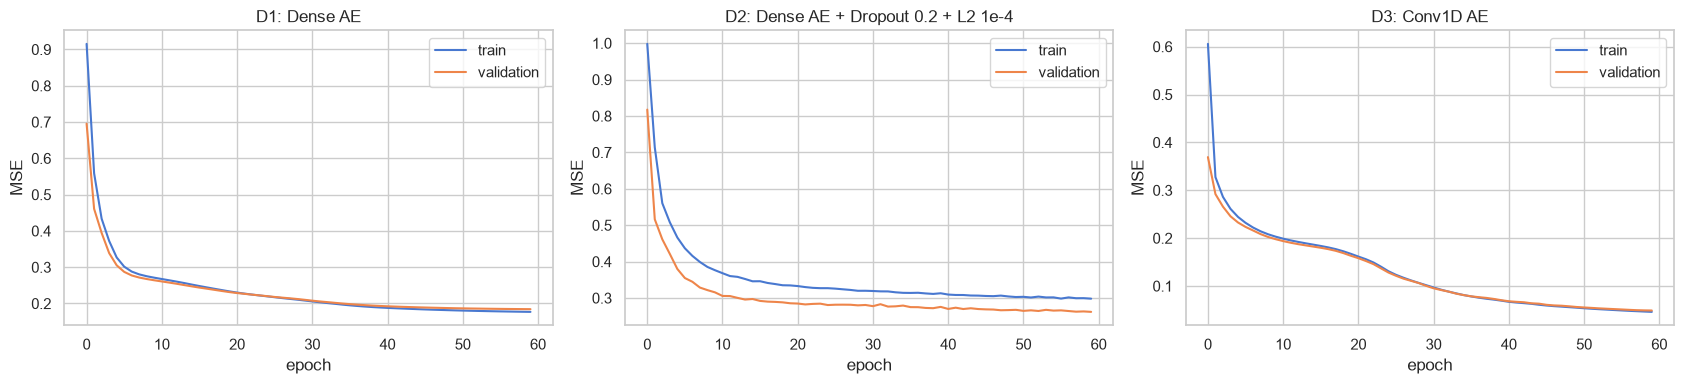

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, run in zip(axes, RUNS):
    ax.plot(histories[run]["loss"], label="train")
    ax.plot(histories[run]["val_loss"], label="validation")
    ax.set_title(f"{run}: {RUNS[run][0]}"); ax.set_xlabel("epoch"); ax.set_ylabel("MSE"); ax.legend()
plt.tight_layout(); plt.show()

## 4. Вибір фінальної моделі (за validation F1) і фінальний test

In [6]:
dl = exp[exp.Run != "B0"]
best_run = dl.loc[dl["Val F1"].idxmax(), "Run"]
print("Обрано за validation:", best_run, "—", RUNS[best_run][0])

final = {}
for run in ["B0", best_run]:
    th = float(exp.loc[exp.Run == run, "threshold"].iloc[0])
    s_te = zscore_scores(Xte) if run == "B0" else recon_error(models[run], Xte)
    final[run] = (s_te, th)

metrics = pd.DataFrame({run: evaluate(yte, s, th, WINDOWS_PER_DAY) for run, (s, th) in final.items()}).T
metrics.index = ["B0 baseline", f"{best_run} (final)"]
(Path("..") / "results").mkdir(exist_ok=True)
metrics.round(4).to_csv("../results/metrics.csv")

exp_table = exp.drop(columns="threshold").copy()
exp_table["Decision"] = ["reference"] + ["SELECTED" if r == best_run else "rejected" for r in RUNS]
exp_table.round(4).to_csv("../results/experiments.csv", index=False)
metrics.round(3)

Обрано за validation: D1 — Dense AE


,precision,recall,f1,pr_auc,false_alarms,false_alarms_per_day
B0 baseline,0.311,0.452,0.369,0.433,115.0,4.834
D1 (final),0.689,0.713,0.701,0.785,37.0,1.555


## 5. Error analysis

In [7]:
s_b0, th_b0 = final["B0"]
s_dl, th_dl = final[best_run]
by_type = recall_by_type(yte, tte, s_b0, th_b0).rename(columns={"recall": "recall B0"})
by_type[f"recall {best_run}"] = recall_by_type(yte, tte, s_dl, th_dl)["recall"]
by_type.round(3).to_csv("../results/recall_by_type.csv", index=False)
by_type.round(3)

,anomaly_type,windows,recall B0,recall D1
0,spike,23,1.000,1.000
1,level_shift,21,0.333,0.667
2,vib_oscillation,10,1.000,0.900
3,decorrelation,61,0.197,0.590


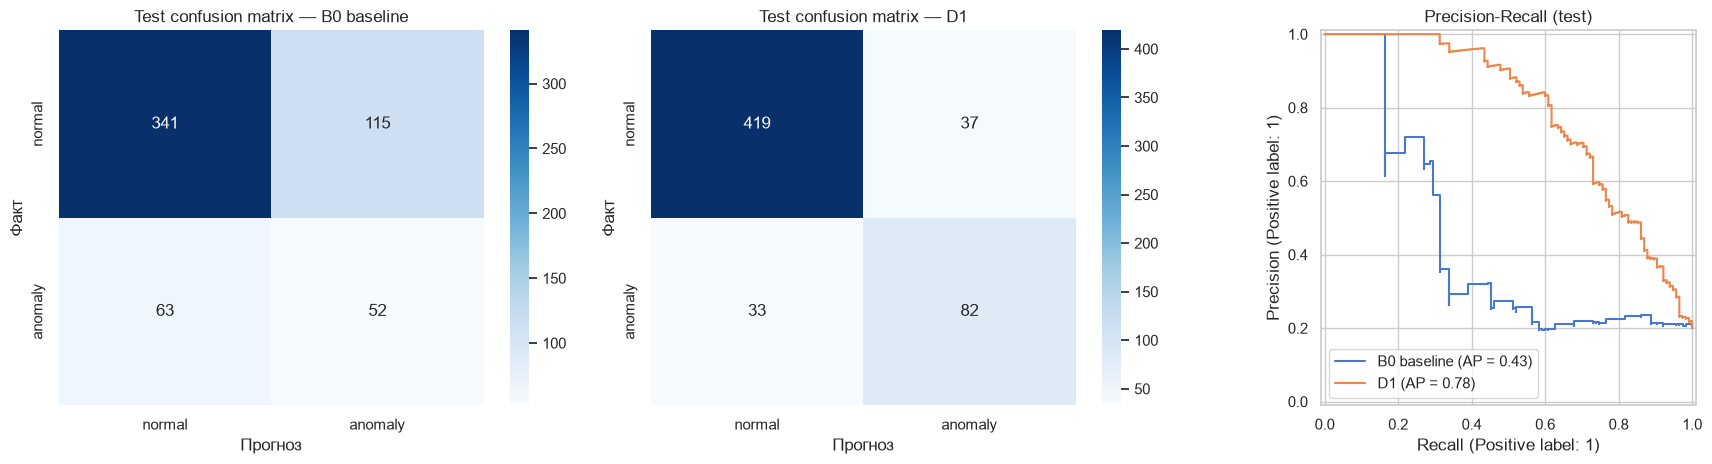

In [8]:
from sklearn.metrics import confusion_matrix, PrecisionRecallDisplay
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
for ax, (name, s, th) in zip(axes[:2], [("B0 baseline", s_b0, th_b0), (best_run, s_dl, th_dl)]):
    sns.heatmap(confusion_matrix(yte, s > th), annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=["normal", "anomaly"], yticklabels=["normal", "anomaly"])
    ax.set_title(f"Test confusion matrix — {name}"); ax.set_xlabel("Прогноз"); ax.set_ylabel("Факт")
PrecisionRecallDisplay.from_predictions(yte, s_b0, ax=axes[2], name="B0 baseline")
PrecisionRecallDisplay.from_predictions(yte, s_dl, ax=axes[2], name=best_run)
axes[2].set_title("Precision-Recall (test)")
plt.tight_layout(); plt.show()

### 5.1 Вплив дрейфу: де виникають хибні тривоги

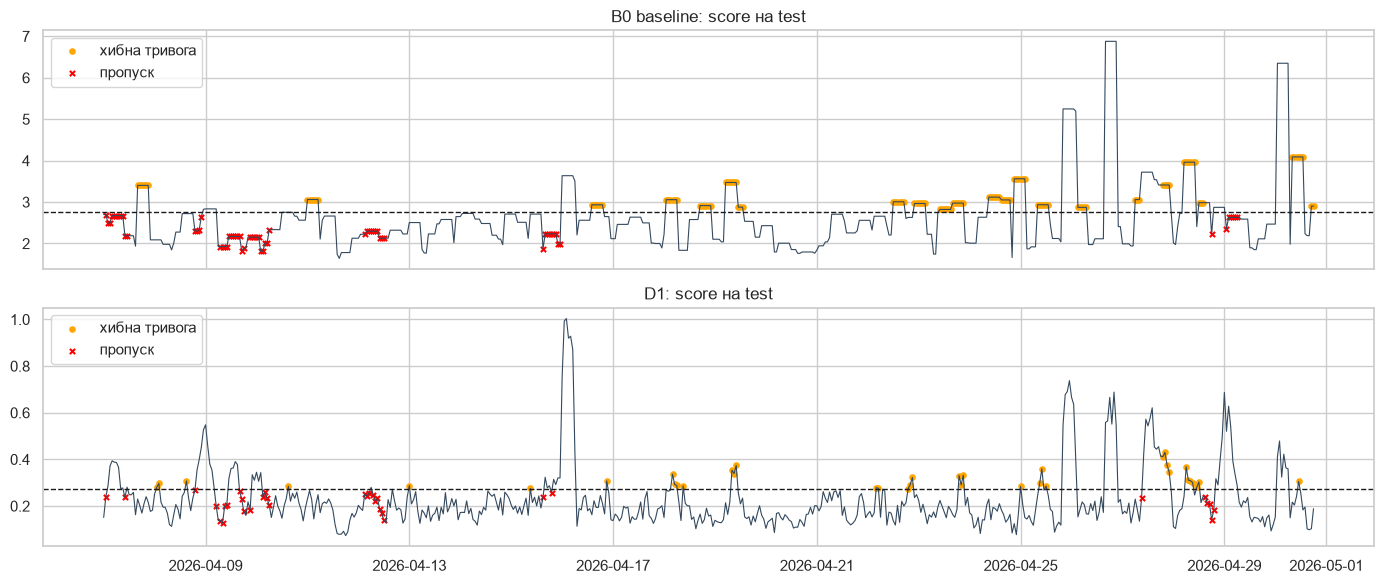

B0: хибні тривоги в 1-й половині test = 28, у 2-й (сильніший дрейф) = 87


In [9]:
te_starts = te.timestamp.iloc[np.arange(0, len(te) - W["window"] + 1, W["step"])].to_numpy()
fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
for ax, (name, s, th) in zip(axes, [("B0 baseline", s_b0, th_b0), (best_run, s_dl, th_dl)]):
    ax.plot(te_starts, s, lw=0.8, color="#34495e")
    ax.axhline(th, color="k", ls="--", lw=1)
    fa = (s > th) & (yte == 0)
    miss = (s <= th) & (yte == 1)
    ax.scatter(te_starts[fa], s[fa], color="orange", s=14, label="хибна тривога")
    ax.scatter(te_starts[miss], s[miss], color="red", s=14, marker="x", label="пропуск")
    ax.set_title(f"{name}: score на test"); ax.legend(loc="upper left")
plt.tight_layout(); plt.show()
fa_b0 = (s_b0 > th_b0) & (yte == 0)
half = len(yte) // 2
print(f"B0: хибні тривоги в 1-й половині test = {fa_b0[:half].sum()}, у 2-й (сильніший дрейф) = {fa_b0[half:].sum()}")

### 5.2 Типові пропуски фінальної моделі

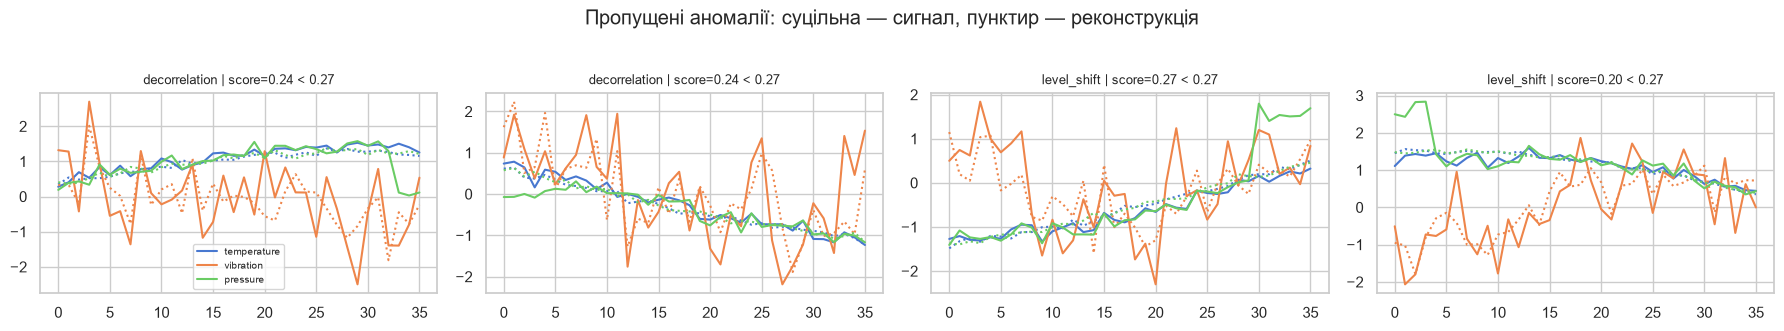

In [10]:
miss_idx = np.where((s_dl <= th_dl) & (yte == 1))[0][:4]
fig, axes = plt.subplots(1, len(miss_idx), figsize=(4.5 * len(miss_idx), 3.2))
for ax, i in zip(np.atleast_1d(axes), miss_idx):
    rec = models[best_run].predict(Xte[i:i+1], verbose=0)[0]
    for c, ch in enumerate(CHANNELS):
        ax.plot(Xte[i, :, c], label=ch)
        ax.plot(rec[:, c], ls=":", color=ax.lines[-1].get_color())
    ax.set_title(f"{tte[i]} | score={s_dl[i]:.2f} < {th_dl:.2f}", fontsize=9)
np.atleast_1d(axes)[0].legend(fontsize=7)
plt.suptitle("Пропущені аномалії: суцільна — сигнал, пунктир — реконструкція", y=1.03)
plt.tight_layout(); plt.show()

## 6. Analytical brief

Підсумковий висновок, обмеження та next step — у `results/error_analysis.md` і `README.md` (заповнені за результатами цього запуску).